<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/geo4bolivia_quickstart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load, link and build Bolivian indicators with `geo4bolivia`

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook is a hands-on tour of the observatory's data for Bolivia's 343 municipalities and indigenous autonomies:

1. **Load data without the package**: every file is a plain URL
2. **Load data with the package** `geo4bolivia`
3. **Move data across scales**: municipalities, provinces, departments and the country
4. **Link your own table** to the observatory's units, by name or by INE code
5. **Build a new indicator from a raster**
6. **Interpolate to a grid**, then **save** your dataset in the observatory's format

The companion notebooks ([list](https://github.com/quarcs-lab/geo4bolivia/tree/main/notebooks)) analyse the same data: exploratory spatial analysis, inequality, geographically weighted regression, and poverty prediction from satellite embeddings.

## 0. Setup

In Google Colab the next cell installs the package (a few seconds: Colab already has its dependencies). Locally, `uv sync` has installed it already.

In [1]:
import importlib.util

if importlib.util.find_spec("geo4bolivia") is None:
    !pip install -q "geo4bolivia[raster]" mapclassify

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

## 1. Load data without the package

Every published file is a plain URL, so pandas, geopandas, R, Stata or Excel can read it directly. Three kinds of files matter:

- **`data/<scale>/<dataset>.csv`**: the indicators, as a panel with one row per unit (`geo_id`) and year
- **`geo/units.csv`**: names, parent units and the codes other sources use (INE, DS4Bolivia, GADM)
- **`geo/boundaries/<scale>.geojson`**: polygons, keyed by the same `geo_id`

In [3]:
BASE = "https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/"

# Inside a clone of the repository, read the local files instead (Colab uses the URLs)
local = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "geo" / "units.csv").is_file()), None)
if local is not None:
    BASE = local.as_posix() + "/"

sdg01 = pd.read_csv(BASE + "data/municipality/sdg01.csv")              # 343 units x 2 periods
units = pd.read_csv(BASE + "geo/units.csv", dtype={"ine_code": str})   # 466 units at 4 scales
municipalities = gpd.read_file(BASE + "geo/boundaries/municipality.geojson")

sdg01.head()

,geo_id,year,mun_id,index_sdg1,sdg1_2_mpi,sdg1_4_eep,sdg1_4_nbi,sdg1_4_ssb
0,BO-01-01-01,2012,10201,11.7,0.512,87.2,87.7,12.8
1,BO-01-01-01,2024,10201,35.7,0.187,82.0,71.7,29.6
2,BO-01-01-02,2012,10202,14.0,0.452,89.9,86.9,13.1
3,BO-01-01-02,2024,10202,38.9,0.133,84.6,69.7,33.5
4,BO-01-02-01,2012,10801,38.9,0.267,70.3,67.1,40.4


The SDG data come from the [Atlas de los ODS en Bolivia 2026](https://atlasods.sdsnbolivia.org/) (Andersen & Argandoña, SDSN Bolivia). Each indicator has two values, an initial one stored at **2012** and a final one stored at **2024**, the years of the last two censuses. The Multidimensional Poverty Index (`sdg1_2_mpi`, 0 to 1, higher = poorer) comes from the censuses themselves, so its values refer exactly to 2012 and 2024. With the same classes in both maps, the change is plain to see:

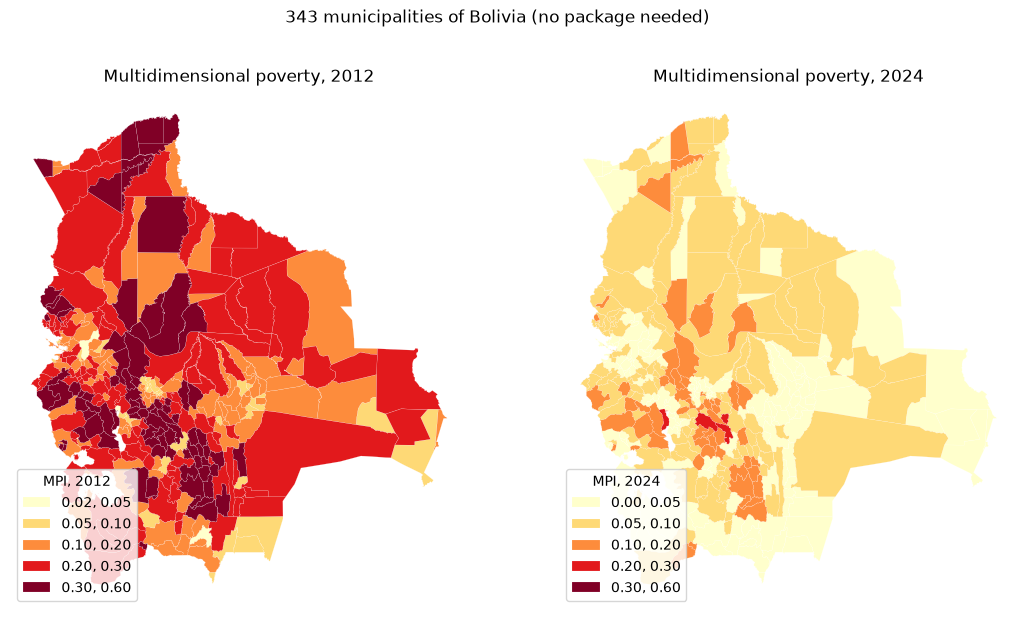

In [4]:
mpi_map = municipalities.merge(sdg01[["geo_id", "year", "sdg1_2_mpi"]], on="geo_id")
bins = {"bins": [0.05, 0.1, 0.2, 0.3, 0.6]}

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, year in zip(axes, [2012, 2024]):
    mpi_map[mpi_map["year"] == year].plot(
        column="sdg1_2_mpi", cmap="YlOrRd", scheme="user_defined", classification_kwds=bins,
        legend=True, legend_kwds={"title": f"MPI, {year}", "loc": "lower left"},
        edgecolor="white", linewidth=0.1, ax=ax)
    ax.set_axis_off()
    ax.set_title(f"Multidimensional poverty, {year}")
fig.suptitle("343 municipalities of Bolivia (no package needed)");

## 2. Load data with the package

The package does the same in one line, and more: it lists the datasets, describes their variables, filters years and variables, reshapes, and attaches boundaries.

In [5]:
import geo4bolivia as geo

geo.datasets()

,dataset,scale,title,first_year,last_year,variables,csv,parquet
0,pop,municipality,Population,2001,2020,2,data/municipality/pop.csv,data/municipality/pop.parquet
1,ntl,municipality,Night-time lights per capita,2012,2020,2,data/municipality/ntl.csv,data/municipality/ntl.parquet
2,sdg,municipality,"Sustainable Development Index, IDS (SDG Atlas ...",2012,2024,4,data/municipality/sdg.csv,data/municipality/sdg.parquet
3,sdg01,municipality,SDG 1: No poverty (SDG Atlas of Bolivia 2026),2012,2024,5,data/municipality/sdg01.csv,data/municipality/sdg01.parquet
4,sdg02,municipality,SDG 2: Zero hunger (SDG Atlas of Bolivia 2026),2012,2024,8,data/municipality/sdg02.csv,data/municipality/sdg02.parquet
5,sdg03,municipality,SDG 3: Good health and well-being (SDG Atlas o...,2012,2024,8,data/municipality/sdg03.csv,data/municipality/sdg03.parquet
6,sdg04,municipality,SDG 4: Quality education (SDG Atlas of Bolivia...,2012,2024,12,data/municipality/sdg04.csv,data/municipality/sdg04.parquet
7,sdg05,municipality,SDG 5: Gender equality (SDG Atlas of Bolivia 2...,2012,2024,7,data/municipality/sdg05.csv,data/municipality/sdg05.parquet
8,sdg06,municipality,SDG 6: Clean water and sanitation (SDG Atlas o...,2012,2024,4,data/municipality/sdg06.csv,data/municipality/sdg06.parquet
9,sdg07,municipality,SDG 7: Affordable and clean energy (SDG Atlas ...,2012,2024,5,data/municipality/sdg07.csv,data/municipality/sdg07.parquet


In [6]:
geo.dictionary("sdg01")     # every variable: label, description, unit, aggregation rule, source

,variable,label,description,unit,role,aggregation,source
0,geo_id,Municipality ID,GDO-Bolivia municipality geo ID (BO-DD-PP-MM) ...,,id,,
1,year,Period,Period of the values in the row: 2012 holds th...,,time,,
2,mun_id,INE municipality code,Official municipality code of the National Sta...,,source_key,,Atlas de los ODS en Bolivia 2026
3,index_sdg1,No poverty index (0-100),SDG 1 (No poverty) index of the Atlas de los O...,index (0-100),variable,none,Atlas de los ODS en Bolivia 2026
4,sdg1_2_mpi,Multidimensional poverty index (0-1),"Multidimensional poverty index MPI = A × H, wh...",index (0-1),variable,none,Atlas de los ODS en Bolivia 2026
5,sdg1_4_eep,Energy poverty (% of dwellings),Percentage of dwellings whose annual residenti...,% of dwellings,variable,none,Atlas de los ODS en Bolivia 2026
6,sdg1_4_nbi,Unsatisfied basic needs (% of population),Percentage of the population in private dwelli...,% of population,variable,none,Atlas de los ODS en Bolivia 2026
7,sdg1_4_ssb,Access to the 3 basic services (% of households),Percentage of private dwellings with people pr...,% of households,variable,none,Atlas de los ODS en Bolivia 2026


The Atlas is published as one dataset per goal (`sdg01` to `sdg17`; it has no index for goals 12 and 14), each with the goal's index (`index_sdgN`, 0–100, higher = better) and its indicators, and a dataset `sdg` with the overall **Sustainable Development Index** (IDS, `index_sdg`), its ranking and the census population. Not every indicator was measured in a census year: the description of each variable gives its actual reference years (energy poverty, for example, refers to 2016 and 2024).

`geometry=True` returns a GeoDataFrame, ready to map; `wide=` gives one column per period, convenient for changes:

,index_sdg2012,index_sdg2024,change
count,343.0,343.0,343.0
mean,50.1,60.1,10.0
std,5.8,5.3,2.9
min,37.2,47.3,-2.7
25%,46.0,56.4,8.3
50%,49.6,59.8,9.9
75%,53.4,63.7,11.8
max,70.5,77.3,20.5


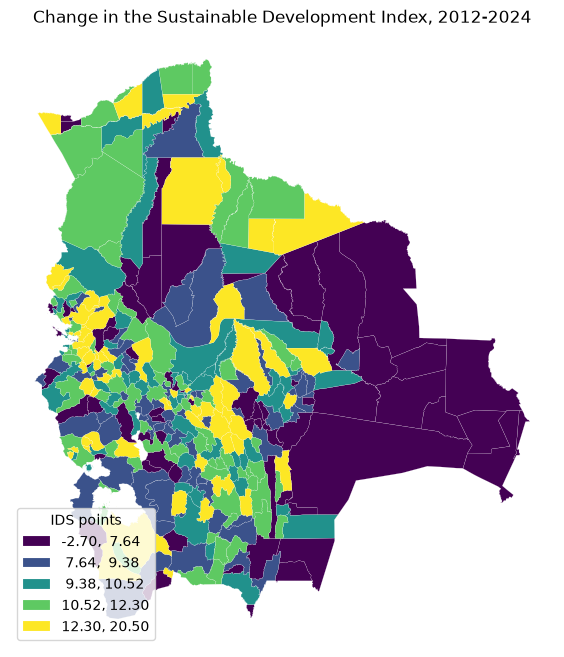

In [7]:
ids = geo.load("sdg", variables="index_sdg", wide="index_sdg")
ids["change"] = ids["index_sdg2024"] - ids["index_sdg2012"]

gdf = geo.boundaries("municipality").merge(ids, on="geo_id")
ax = gdf.plot(column="change", cmap="viridis", scheme="quantiles", k=5, legend=True,
              legend_kwds={"title": "IDS points", "loc": "lower left"}, edgecolor="white", linewidth=0.1,
              figsize=(8, 8))
ax.set_axis_off()
ax.set_title("Change in the Sustainable Development Index, 2012-2024")
ids.describe().round(1)

The average municipality's IDS rose from 50.1 to 60.1 points (median change 9.9). Only San José de Chiquitos (Santa Cruz, -2.7) went backwards; Cruz de Machacamarca and Carangas (Oruro) gained about 20 points.

In [8]:
# The package can attach the boundaries itself; here the IDS of 2024, best and worst
best = geo.load("sdg", variables=["index_sdg", "rank_sdg"], years=2024, geometry=True)
pd.concat([best.nsmallest(3, "rank_sdg"), best.nlargest(3, "rank_sdg")])[["geo_id", "name", "index_sdg", "rank_sdg"]]

,geo_id,name,index_sdg,rank_sdg
161,BO-04-17-04,Nuestra Señora de La Paz,77.3,1
336,BO-09-03-01,Tarija,74.5,2
13,BO-01-06-02,Sucre,74.4,3
63,BO-02-12-04,TIOC-Raqaypampa,47.3,343
273,BO-07-16-02,Tinguipaya,48.4,342
243,BO-07-04-02,Ocurí,49.2,341


In 2024 the capitals Nuestra Señora de La Paz, Tarija and Sucre rank first; the last places go to TIOC-Raqaypampa, one of the four units created after 2012, and to Tinguipaya and Ocurí in Potosí.

In [9]:
# A window of years and a variable from another dataset
lights = geo.load("ntl", years=(2012, 2016), variables=["ln_NTLpc"])
lights.head(3)

,geo_id,year,ln_NTLpc
0,BO-01-01-01,2012,11.136693
1,BO-01-01-01,2013,11.400161
2,BO-01-01-01,2014,11.328924


In [10]:
# names, parents, and the codes each source uses: GADM (gid), INE (ine_code, mun_id), DS4Bolivia (asdf_id)
geo.units("municipality").head(3)

,geo_id,scale,name,parent_id,country_id,department_id,province_id,municipality_id,gid,ine_code,asdf_id,mun_id,name_ds4bolivia,name_gadm,area_km2
0,BO-01-01-01,municipality,Azurduy,BO-01-01,BO,BO-01,BO-01-01,BO-01-01-01,BOL.1.1.1_2,010201,174,10201,Azurduy,Azurduy,1729.28
1,BO-01-01-02,municipality,Tarvita,BO-01-01,BO,BO-01,BO-01-01,BO-01-01-02,BOL.1.1.2_2,010202,186,10202,Tarvita,Tarvita,1354.24
2,BO-01-02-01,municipality,Villa Serrano,BO-01-02,BO,BO-01,BO-01-02,BO-01-02-01,BOL.1.2.1_2,010801,246,10801,Villa Serrano,VillaSerrano,1730.36


## 3. Move data across scales

Each scale nests in the coarser ones, and each variable's metadata says how it may be aggregated: `sum` for totals such as population, `none` for logs, rates and indices that need weights.

In [11]:
geo.scales()          # the registry of scales

,label,kind,parent,children,id_pattern,example,status
scale,,,,,,,
country,Country,admin,None,None,^BO$,BO,active
department,Department,admin,country,None,^BO-\d{2}$,BO-04,active
province,Province,admin,department,None,^BO-\d{2}-\d{2}$,BO-04-17,active
municipality,Municipality (343),admin,province,None,^BO-\d{2}-\d{2}-\d{2}$,BO-04-17-04,active
municipality_ine,Municipality (current INE map),custom,None,None,^BO-INE-\d{6}$,BO-INE-020101,planned
grid10k,10 km grid cell,grid,None,None,^BO-G10K-r\d{3}c\d{3}$,BO-G10K-r012c034,planned


The census population is in the `sdg` dataset, in both census years:

In [12]:
census = geo.load("sdg", variables="population")
by_department = geo.aggregate(census, to="department", dataset="sdg")    # 343 municipalities -> 9 departments
by_department = by_department.pivot(index="geo_id", columns="year", values="population").reset_index()
by_department["growth_%"] = (100 * (by_department[2024] / by_department[2012] - 1)).round(1)
by_department.merge(geo.units("department")[["geo_id", "name"]], on="geo_id").sort_values(2024, ascending=False)

,geo_id,2012,2024,growth_%,name
7,BO-08,2657762,3122605,17.5,Santa Cruz
3,BO-04,2719344,3030517,11.4,La Paz
1,BO-02,1762761,2016357,14.4,Cochabamba
6,BO-07,828517,861292,4.0,Potosí
0,BO-01,580923,606027,4.3,Chuquisaca
4,BO-05,494587,571471,15.5,Oruro
8,BO-09,483518,534210,10.5,Tarija
2,BO-03,422008,488260,15.7,Beni
5,BO-06,110436,134194,21.5,Pando


Santa Cruz overtook La Paz as the most populous department; Pando grew fastest (22%), Potosí and Chuquisaca slowest (4%).

Poverty is a rate, so its departmental value is a **population-weighted** mean. `weights=` brings the census population of the same period:

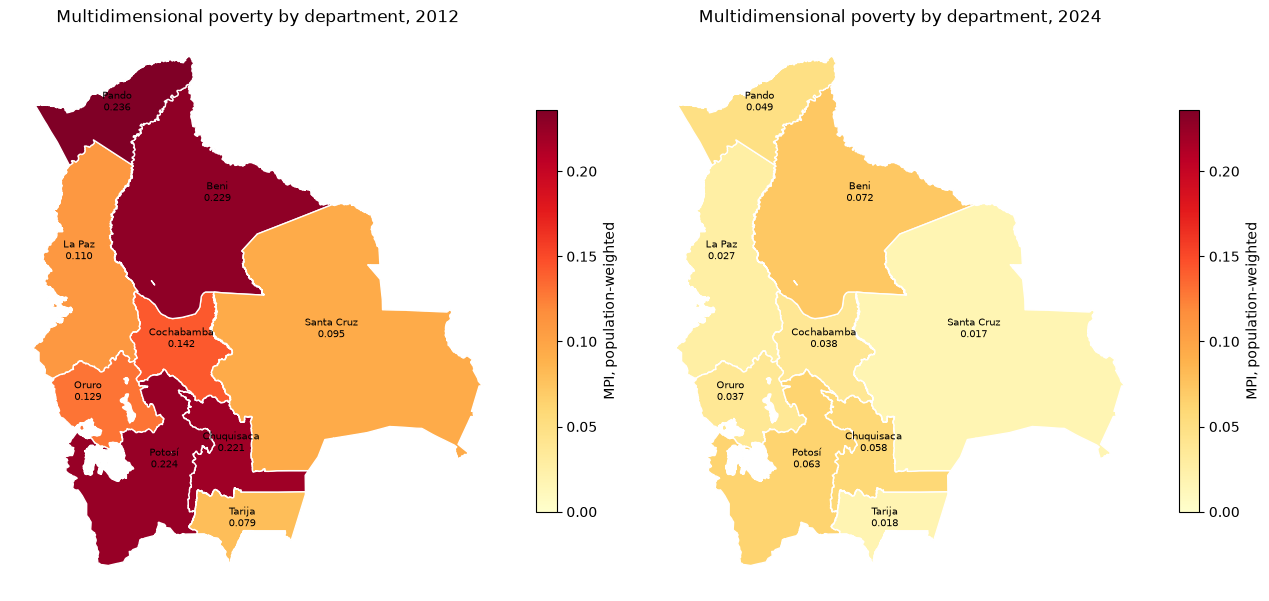

In [13]:
mpi = geo.load("sdg01", variables="sdg1_2_mpi")
mpi_dep = geo.aggregate(mpi, to="department", rules={"sdg1_2_mpi": "weighted_mean:population"}, weights=census)
mpi_dep = geo.boundaries("department").merge(mpi_dep, on="geo_id")

fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, year in zip(axes, [2012, 2024]):
    d = mpi_dep[mpi_dep["year"] == year]
    d.plot(column="sdg1_2_mpi", cmap="YlOrRd", vmin=0, vmax=mpi_dep["sdg1_2_mpi"].max(), legend=True,
           edgecolor="white", ax=ax, legend_kwds={"label": "MPI, population-weighted", "shrink": 0.6})
    for _, row in d.iterrows():
        p = row.geometry.representative_point()
        ax.annotate(f"{row['name']}\n{row['sdg1_2_mpi']:.3f}", (p.x, p.y), ha="center", fontsize=7)
    ax.set_axis_off()
    ax.set_title(f"Multidimensional poverty by department, {year}")
plt.tight_layout()

In [14]:
national = geo.aggregate(mpi, to="country", rules={"sdg1_2_mpi": "weighted_mean:population"}, weights=census)
national

,geo_id,year,sdg1_2_mpi,n_units
0,BO,2012,0.133185,343
1,BO,2024,0.033046,343


Multidimensional poverty fell sharply. The population-weighted national MPI dropped from 0.133 in 2012 to 0.033 in 2024, and each department's to between 18% and 32% of its 2012 value. In 2012 Pando (0.236), Beni, Potosí and Chuquisaca were the poorest departments and Tarija (0.079) the least poor; in 2024 Beni (0.072) and Potosí are the poorest and Santa Cruz (0.017) and Tarija the least poor.

`geo.combine()` loads several datasets at one scale, aggregating finer ones on the way. Here night-time lights and WorldPop population meet poverty in 2012. Lights and WorldPop cover **333 of the 343 units**: they were computed on the older 339-unit map, so the six municipalities that have since lost territory and the four new units have no values. The inner merge keeps the 333. The relation is a classic one: brighter municipalities are less poor.

units with lights, population and poverty: 333
correlation: -0.54


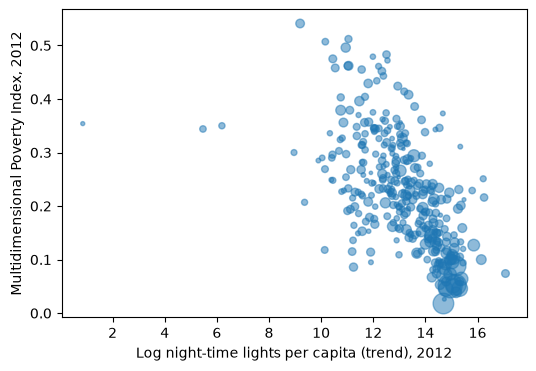

In [15]:
panel = geo.combine(["ntl", "pop"], scale="municipality", years=2012).merge(mpi, on=["geo_id", "year"])
print(f"units with lights, population and poverty: {len(panel)}")

ax = panel.plot.scatter(x="ln_t400NTLpc", y="sdg1_2_mpi", s=np.sqrt(panel["pop"]) / 4, alpha=0.5, figsize=(6, 4))
ax.set_xlabel("Log night-time lights per capita (trend), 2012"); ax.set_ylabel("Multidimensional Poverty Index, 2012")
print(f"correlation: {panel['ln_t400NTLpc'].corr(panel['sdg1_2_mpi']):.2f}")

The correlation is -0.54 across the 333 units.

## 4. Link your own table

Tables from reports and ministries identify units by name, spelled in many ways, or by INE code. `geo.link()` attaches the observatory's `geo_id`. It ignores accents, case, spaces and punctuation, and tries every name and code column in `geo.units()`.

The values below are **made up** for the demonstration; replace them with your own data.

In [16]:
mine = pd.DataFrame({
    "Departamento": ["LA PAZ", "Cochabamba", "Santa Cruz", "Potosi", "Chuquisaca", "La Paz"],
    "year":         [2024, 2024, 2024, 2024, 2024, 2025],
    "clinics":      [412, 301, 388, 266, 190, 420],          # illustrative values
})
mine = geo.link(mine, scale="department", on="Departamento")
mine

,geo_id,Departamento,year,clinics
0,BO-04,LA PAZ,2024,412
1,BO-02,Cochabamba,2024,301
2,BO-08,Santa Cruz,2024,388
3,BO-07,Potosi,2024,266
4,BO-01,Chuquisaca,2024,190
5,BO-04,La Paz,2025,420


In [17]:
geo.check(mine, scale="department")        # [] = a valid panel: known ids, one row per unit and year

[]

Municipal statistics from INE (and every DS4Bolivia table) carry codes. Link them by code: INE's 6-digit `ine_code`, the same code as a number (`mun_id`), or DS4Bolivia's `asdf_id`. The names follow the Atlas, so the capital is *Nuestra Señora de La Paz*:

In [18]:
ine = pd.DataFrame({"codigo": [20101, 20105, 70101, 30101, 10101], "teachers": [9120, 6211, 11034, 5980, 2870]})
geo.link(ine, scale="municipality", on="codigo", key="mun_id").merge(
    geo.units("municipality")[["geo_id", "name"]], on="geo_id")

,geo_id,codigo,teachers,name
0,BO-04-17-04,20101,9120,Nuestra Señora de La Paz
1,BO-04-17-02,20105,6211,El Alto
2,BO-08-01-05,70101,11034,Santa Cruz de la Sierra
3,BO-02-08-01,30101,5980,Cochabamba
4,BO-01-06-02,10101,2870,Sucre


Older spellings still link: by default `geo.link()` also tries `name_ds4bolivia` and `name_gadm`, so "La Paz" finds the capital.

In [19]:
geo.link(pd.DataFrame({"m": ["La Paz", "Potosi"]}), scale="municipality", on="m")

,geo_id,m
0,BO-04-17-04,La Paz
1,BO-07-16-01,Potosi


A name shared by several municipalities, or a typo, stops with an explanation instead of silently linking the wrong unit:

In [20]:
for value in ["San Javier", "Cochabmba"]:
    try:
        geo.link(pd.DataFrame({"m": [value]}), scale="municipality", on="m", key="name")
    except ValueError as err:
        print(err, "\n")

1 row(s) of 'm' name several municipality units and were not linked: 'San Javier' (BO-03-01-01, BO-08-10-04). Link them by a code (key=...) instead. 

1 value(s) of 'm' match no municipality 'name': 'Cochabmba' (did you mean 'Cochabamba'?). Fix them, e.g. df['m'] = df['m'].replace({...}), or pass errors='warn'. 



## 5. Build a new indicator from a raster

`geo.zonal()` summarises any GeoTIFF (for example an export from Google Earth Engine, or a WorldPop population grid) over the units of a scale. As a self-contained example, we compute a raster of **distance to the nearest of Bolivia's three largest cities** (La Paz, Cochabamba and Santa Cruz de la Sierra, the "central axis"), a simple proxy of market access, and average it over municipalities.

In [21]:
import rasterio
from rasterio.transform import from_bounds

CITIES = {"La Paz": (-16.4955, -68.1336), "Cochabamba": (-17.3895, -66.1568), "Santa Cruz": (-17.7833, -63.1821)}

x0, y0, x1, y1 = geo.boundaries("country").total_bounds
nx, ny = 900, 1000                                             # about 1.5 km pixels
LON, LAT = np.meshgrid(np.linspace(x0, x1, nx), np.linspace(y1, y0, ny))

def haversine_km(lat, lon, lat0, lon0):
    lat, lon, lat0, lon0 = map(np.radians, (lat, lon, lat0, lon0))
    a = np.sin((lat - lat0) / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin((lon - lon0) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

km = np.min([haversine_km(LAT, LON, la, lo) for la, lo in CITIES.values()], axis=0)

with rasterio.open("distance_to_main_cities.tif", "w", driver="GTiff", width=nx, height=ny, count=1,
                   dtype="float32", crs="EPSG:4326", transform=from_bounds(x0, y0, x1, y1, nx, ny)) as dst:
    dst.write(km.astype("float32"), 1)

access = geo.zonal("distance_to_main_cities.tif", scale="municipality", stats=["mean", "max"], name="dist_axis_km")
access.head()

,geo_id,dist_axis_km_mean,dist_axis_km_max
0,BO-01-01-01,297.976007,328.039978
1,BO-01-01-02,265.125369,289.335236
2,BO-01-02-01,176.702818,197.327393
3,BO-01-03-01,325.066672,367.762909
4,BO-01-03-02,265.958876,325.305908


Is distance to the central axis associated with poverty, and has that changed? Join the new indicator to the poverty data of both periods:

2012: correlation 0.14
2024: correlation 0.04


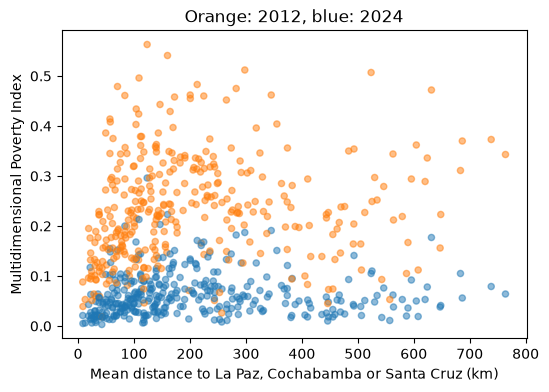

In [22]:
d = mpi.merge(access, on="geo_id")
ax = d.plot.scatter(x="dist_axis_km_mean", y="sdg1_2_mpi", c=d["year"].map({2012: "tab:orange", 2024: "tab:blue"}),
                    alpha=0.5, figsize=(6, 4))
ax.set_xlabel("Mean distance to La Paz, Cochabamba or Santa Cruz (km)")
ax.set_ylabel("Multidimensional Poverty Index")
ax.set_title("Orange: 2012, blue: 2024")
for year, g in d.groupby("year"):
    print(f"{year}: correlation {g['dist_axis_km_mean'].corr(g['sdg1_2_mpi']):.2f}")

Only weakly: municipalities far from the three cities were slightly poorer in 2012 (correlation 0.14), and by 2024 the association has almost vanished (0.04).

## 6. Interpolate to a grid and save

Grids, watersheds or a different municipality map do not nest in the administrative hierarchy. `geo.overlay()` moves data onto them by area weights. Totals (`extensive`) are split by area; rates (`intensive`) are area-weighted means.

municipalities: 11,364,933  grid: 11,364,933


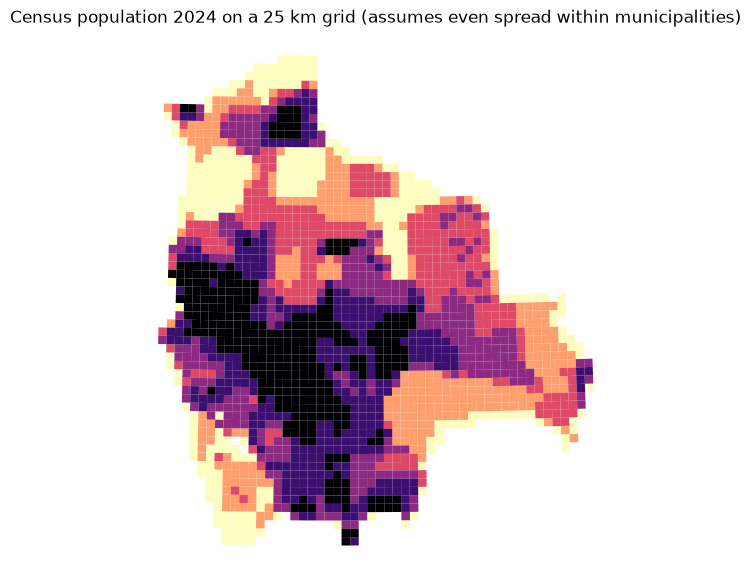

In [23]:
from shapely.geometry import box

crs = geo.config()["equal_area_crs"]                          # Albers equal-area fitted to Bolivia, metres
country = geo.boundaries("country").to_crs(crs)
gx0, gy0, gx1, gy1 = country.total_bounds
size = 25_000
cells = [box(x, y, x + size, y + size) for x in np.arange(gx0, gx1, size) for y in np.arange(gy0, gy1, size)]
grid = gpd.GeoDataFrame({"cell": [f"c{i}" for i in range(len(cells))]}, geometry=cells, crs=crs)
grid = grid[grid.intersects(country.geometry.iloc[0])].to_crs("EPSG:4326")

census_2024 = census[census["year"] == 2024]
on_grid = geo.overlay(census_2024, grid, extensive=["population"], id_col="cell")
print(f"municipalities: {census_2024['population'].sum():,.0f}  grid: {on_grid['population'].sum():,.0f}")   # totals are kept

ax = grid.merge(on_grid.rename(columns={"geo_id": "cell"}), on="cell").plot(
    column="population", cmap="magma_r", scheme="quantiles", k=6, figsize=(7, 7))
ax.set_axis_off(); ax.set_title("Census population 2024 on a 25 km grid (assumes even spread within municipalities)");

Finally, save your indicator exactly like the published datasets: CSV, Parquet and a Frictionless datapackage describing every variable. It is then easy to share, reload or contribute to the observatory ([CONTRIBUTING_DATA.md](https://github.com/quarcs-lab/geo4bolivia/blob/main/CONTRIBUTING_DATA.md)).

In [24]:
access["year"] = 2024
geo.save(access[["geo_id", "year", "dist_axis_km_mean", "dist_axis_km_max"]], "market_access", scale="municipality",
         directory="my_data", title="Distance to the central axis",
         description="Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.",
         variables={"dist_axis_km_mean": {"description": "Mean distance to the nearest main city", "unit": "km", "aggregation": "none"},
                    "dist_axis_km_max": {"description": "Maximum distance to the nearest main city", "unit": "km", "aggregation": "max"}})

wrote my_data/data/municipality/market_access.csv, my_data/data/municipality/market_access.parquet and my_data/metadata/market_access.datapackage.json


{'name': 'market_access',
 'title': 'Distance to the central axis',
 'description': 'Mean and maximum straight-line distance from each municipality to the nearest of La Paz, Cochabamba and Santa Cruz de la Sierra.',
 'version': '1.0.0',
 'licenses': [{'name': 'CC-BY-4.0'}],
 'sources': [],
 'geo:categories': [],
 'geo:notes': [],
 'resources': [{'name': 'market_access-municipality',
   'path': 'https://raw.githubusercontent.com/quarcs-lab/geo4bolivia/main/data/municipality/market_access.csv',
   'format': 'csv',
   'mediatype': 'text/csv',
   'encoding': 'utf-8',
   'geo:scale': 'municipality',
   'geo:period': [2024, 2024],
   'geo:path': 'data/municipality/market_access.csv',
   'geo:parquet': 'data/municipality/market_access.parquet',
   'schema': {'primaryKey': ['geo_id', 'year'],
    'fields': [{'name': 'geo_id',
      'title': 'Municipality (343) ID',
      'type': 'string',
      'description': 'Municipality (343) geo ID',
      'geo:role': 'id',
      'constraints': {'required'

## Next steps

- Explore poverty and lights spatially: [`esda.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb)
- Predict poverty from satellite embeddings: [`embeddings_mpi_ml.ipynb`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/embeddings_mpi_ml.ipynb)
- The full guide: [how the data infrastructure works](https://github.com/quarcs-lab/geo4bolivia/blob/main/docs/data-infrastructure.md)
- Every function has help: `help(geo.link)`